## Architettura

L’encoder riduce la risoluzione e produce un vettore latente da 64 dimensioni; il decoder ricostruisce un’immagine in `[0, 1]`.


## Training e valutazione

Il checkpoint usa la validation MSE; il test confronta modello e baseline rumorosa con MSE, PSNR e SSIM.


# 2. AutoEncoder per il denoising

Qui costruiamo il dataset noisy/clean, definiamo un AutoEncoder convoluzionale e osserviamo il miglioramento rispetto alla baseline dell’immagine rumorosa.


## Architettura

L’encoder riduce la risoluzione da `64x64` a `16x16` e comprime poi la rappresentazione in un vettore latente da 64 dimensioni. Il decoder esegue il percorso inverso e usa `Sigmoid` per produrre valori in `[0, 1]`.


## Training e valutazione

Il checkpoint viene scelto sulla validation reconstruction MSE. Sul test calcoliamo MSE globale, PSNR e SSIM, confrontando sempre anche l’input rumoroso senza modello.


# 2. Dataset noisy/clean, AutoEncoder e training


In [3]:
from pathlib import Path

import sys

import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torchvision.datasets import EuroSAT

ROOT = Path.cwd()
while not (ROOT / "README.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from eurosat_denoising.utils import *
from eurosat_denoising.models import ConvAutoencoder
from eurosat_denoising.training import evaluate

# Fissiamo il seme per rendere riproducibili split e rumore.
seed_everything(42)

DATA = ROOT / "data"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Cartella progetto: {ROOT}")
print(f"Device di calcolo: {DEVICE}")


dataset = EuroSAT(DATA, download=False)
n = len(dataset)

indices = list(range(len(dataset)))
labels = list(dataset.targets)
train_idx, remainder, _, remainder_labels = train_test_split(
    indices, labels, test_size=0.30, random_state=42, stratify=labels
)
val_idx, test_idx = train_test_split(
    remainder, test_size=0.5, random_state=42, stratify=remainder_labels
)

corrupt = lambda image: add_gaussian_noise(image, 0.15)

train_dataset = NoisyCleanDataset(dataset, train_idx, corrupt)
val_dataset = NoisyCleanDataset(dataset, val_idx, corrupt, seed=1000)
test_dataset = NoisyCleanDataset(dataset, test_idx, corrupt, seed=2000)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128)
test_loader = DataLoader(test_dataset, batch_size=128)

split_sizes = [len(train_dataset), len(val_dataset), len(test_dataset)]
print(f"Immagini totali: {n}")
print(f"Split stratificato train/validation/test: {split_sizes}")

# Carichiamo il checkpoint dell'AutoEncoder gia' addestrato (per la presentazione).
model = ConvAutoencoder().to(DEVICE)
model.load_state_dict(torch.load(OUT / "ae_best.pt", map_location=DEVICE))


Cartella progetto: /home/alessandro/Desktop/eurosat-denoising
Device di calcolo: cpu
Immagini totali: 27000
Split stratificato train/validation/test: [18900, 4050, 4050]


<All keys matched successfully>

AE: {'mse': 0.003756874583876182, 'psnr': 24.25173282623291, 'ssim_mean': 0.6094359611655459, 'ssim_std': 0.22598609328269958}
Baseline rumorosa: 0.02117284684514803 16.742243373470103


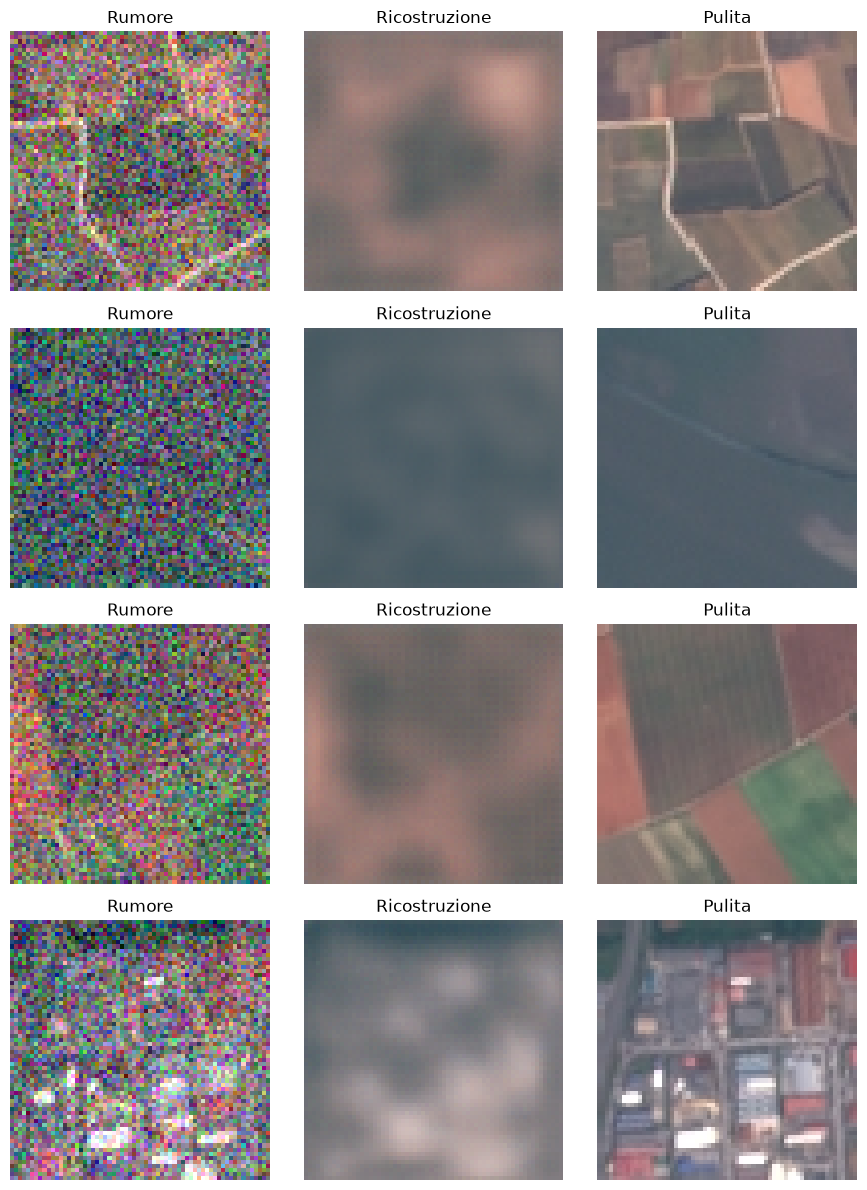

MSE AE: 0.003757 | MSE baseline: 0.021173
PSNR AE: 24.25 dB | PSNR baseline: 16.74 dB


In [4]:
# Valutazione finale: metriche del modello e baseline dell'immagine rumorosa.
# `evaluate` mette il modello in modalita' eval e calcola MSE, PSNR e SSIM.
result = evaluate(model, test_loader, DEVICE)
print("AE:", result)

# La baseline lascia l'immagine rumorosa invariata.
# Confrontarla con l'AE mostra se il denoising migliora davvero l'input.
bm = bp = 0.0
count = 0
with torch.no_grad():
    # NoisyCleanDataset restituisce esattamente `(noisy, clean)`.
    for noisy, clean in test_loader:
        batch_size = len(noisy)
        count += batch_size
        bm += mse_score(noisy, clean) * batch_size
        bp += psnr_score(noisy, clean) * batch_size
baseline_mse = bm / count
baseline_psnr = bp / count
print("Baseline rumorosa:", baseline_mse, baseline_psnr)

# Plot qualitativo: immagine rumorosa -> ricostruzione -> target pulito.
noisy_batch, clean_batch = next(iter(test_loader))
num_examples = min(4, len(noisy_batch))
noisy_batch = noisy_batch[:num_examples].cpu()
clean_batch = clean_batch[:num_examples].cpu()

# Non calcoliamo gradienti durante l'inferenza: riduciamo memoria e costo computazionale.
with torch.no_grad():
    recon_batch = model(noisy_batch.to(DEVICE)).cpu()

fig, axes = plt.subplots(num_examples, 3, figsize=(9, 3 * num_examples), squeeze=False)
for index in range(num_examples):
    # Ogni immagine e' CHW; Matplotlib richiede il formato HWC.
    axes[index, 0].imshow(noisy_batch[index].permute(1, 2, 0).numpy())
    axes[index, 0].set_title("Rumore")
    axes[index, 0].axis("off")

    axes[index, 1].imshow(recon_batch[index].permute(1, 2, 0).numpy())
    axes[index, 1].set_title("Ricostruzione")
    axes[index, 1].axis("off")

    axes[index, 2].imshow(clean_batch[index].permute(1, 2, 0).numpy())
    axes[index, 2].set_title("Pulita")
    axes[index, 2].axis("off")

plt.tight_layout()
plt.show()

# Confronto numerico finale: valori piu' bassi di MSE e piu' alti di PSNR sono migliori.
print(f"MSE AE: {result['mse']:.6f} | MSE baseline: {baseline_mse:.6f}")
print(f"PSNR AE: {result['psnr']:.2f} dB | PSNR baseline: {baseline_psnr:.2f} dB")
